# Phase 2: Hybrid Physics-ML Training, Feature Importance, Uncertainty Propagation & Applicability Domain

This notebook demonstrates the complete Phase 2 hybrid machine-learning workflow:
1. Physics-informed feature extraction (material descriptors, solution descriptors, and engineered physicochemical interactions: $\text{pH} \times T$, $E^0 - \text{ORP}$, $\log_{10}(1+c)$, and Pourbaix passivation stability indicators).
2. Leak-free metal-stratified 5-fold cross-validation comparing **Random Forest**, **Gradient Boosted Trees**, and **Gaussian Process** regressors across $(E_{\text{corr}}, \log_{10} i_{\text{corr}}, \beta_a, \beta_c)$.
3. Feature importance analysis and model bundle serialization.
4. Log-space and physics-clipped Monte Carlo uncertainty propagation ($N = 500$ draws, ADR-0003) producing 90% uncertainty bands on **Polarization Curves** and **Initial Corrosion Rate ($\text{CR}_0$)**.
5. Two-tier **Applicability Domain** evaluation (per-metal Bounding Box + $k$-NN local density) assigning **Confidence Tiers** (`High`, `Medium`, `Low`) and experimental gap guidance.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from corrosion_simulator import (
    ExposureCondition,
    HarmonizedDatabase,
    HybridMLPredictor,
    MLFeatureQuery,
    plot_tafel_uncertainty_band,
    propagate_uncertainty_monte_carlo,
)

db = HarmonizedDatabase.from_directory('data/raw')
echem = db.electrochemical_database
print(f'Loaded {len(echem)} harmonized records across {echem["metal"].nunique()} metals.')
print('Metal counts:', echem['metal'].value_counts().to_dict())
print('Missing ORP_mV count (imputed per fold via training median):', int(echem['ORP_mV'].isna().sum()) if 'ORP_mV' in echem.columns else len(echem))

Loaded 160 harmonized records across 8 metals.
Metal counts: {'Co': 54, 'Ru': 50, 'Ti': 24, 'Mo': 17, 'Cu': 5, 'W': 4, 'Ta': 4, 'Al': 2}
Missing ORP_mV count (imputed per fold via training median): 147


### Dataset Readiness Analysis
All 160 harmonized records span the 8 core semiconductor metals (`Co`, `Ru`, `Ti`, `Mo`, `Cu`, `W`, `Ta`, `Al`). Sparse numeric descriptors such as `ORP_mV` are retained rather than dropped and imputed using strictly training-fold medians inside `ElectrochemicalFeatureExtractor` to prevent data leakage.

In [2]:
cv_rows = []
for family in ('random_forest', 'gradient_boosting', 'gaussian_process'):
    model = HybridMLPredictor(
        model_family=family,
        random_state=42,
        n_estimators=60,
        n_bootstrap=8,
    )
    metrics = model.cross_validate(db, cv_strategy='stratified_5fold')
    for m in metrics:
        cv_rows.append({
            'Model Family': m.model_family,
            'Target': m.target,
            'MAE': round(m.mae, 4),
            'RMSE': round(m.rmse, 4),
            'R2': round(m.r2, 4),
            'MAPE (%)': round(m.mape, 2),
        })

cv_df = pd.DataFrame(cv_rows)
print(cv_df.to_string(index=False))

     Model Family             Target     MAE    RMSE     R2  MAPE (%)
    random_forest        Ecorr_V_SHE  0.1434  0.2043 0.4976    210.19
    random_forest log10_icorr_uA_cm2  0.6525  0.8916 0.7033    125.24
    random_forest      beta_a_mV_dec  9.0794 24.5218 0.7502     10.70
    random_forest      beta_c_mV_dec 11.5234 34.1481 0.3685      6.78
gradient_boosting        Ecorr_V_SHE  0.1595  0.2164 0.4367    196.15
gradient_boosting log10_icorr_uA_cm2  0.7128  0.9585 0.6572    110.07
gradient_boosting      beta_a_mV_dec 13.1848 27.0119 0.6969     16.18
gradient_boosting      beta_c_mV_dec 13.8908 33.1885 0.4035      8.55
 gaussian_process        Ecorr_V_SHE  0.1461  0.1993 0.5219    195.24
 gaussian_process log10_icorr_uA_cm2  0.7137  0.9746 0.6456    135.59
 gaussian_process      beta_a_mV_dec 12.1460 26.7683 0.7024     13.87
 gaussian_process      beta_c_mV_dec 13.6178 33.1011 0.4067      8.36


### Cross-Validation Model Comparison
The table above compares Random Forest, Gradient Boosted Trees, and Gaussian Process regressors under identical metal-stratified 5-fold splits with leak-free in-fold preprocessing. Predicting $\log_{10}(i_{\text{corr}})$ stabilizes errors across orders of magnitude in corrosion current density while keeping $E_{\text{corr}}$ and Tafel slopes well-behaved.

Serialized and reloaded model bundle (1982.5 KB) cleanly.


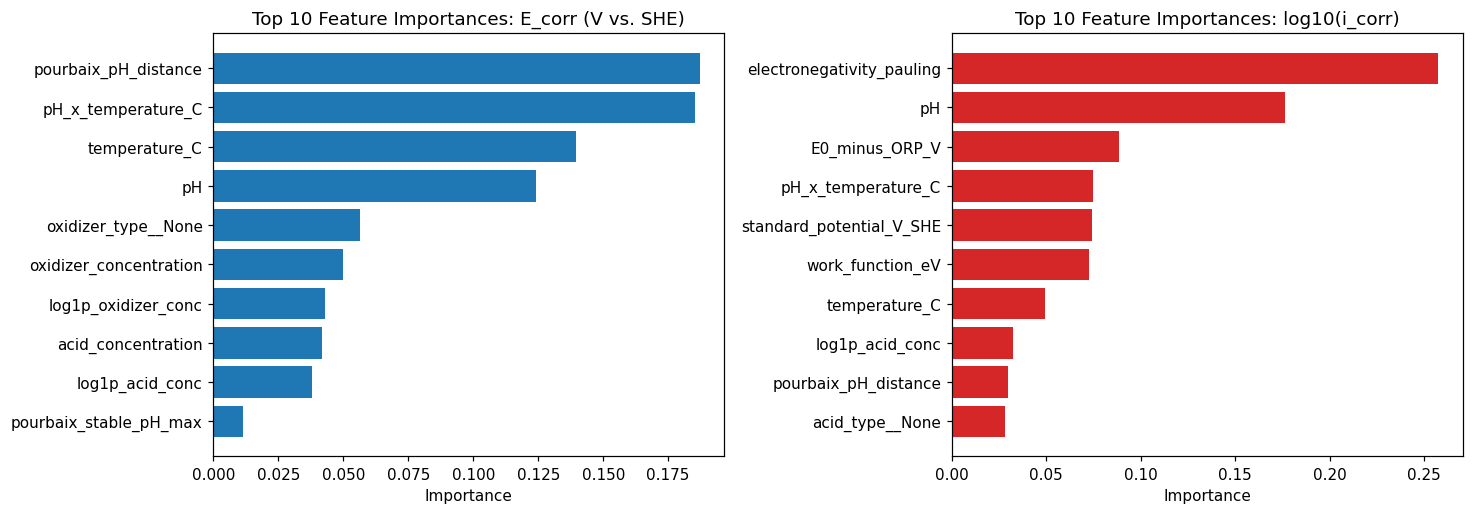

In [3]:
rf_predictor = HybridMLPredictor(model_family='random_forest', random_state=42, n_estimators=100)
rf_predictor.fit(db)

# Verify model persistence round-trip
import tempfile
with tempfile.TemporaryDirectory() as tmpdir:
    bundle_path = rf_predictor.save(Path(tmpdir) / 'rf_predictor.joblib')
    reloaded = HybridMLPredictor.load(bundle_path)
    print(f'Serialized and reloaded model bundle ({bundle_path.stat().st_size / 1024:.1f} KB) cleanly.')

imp_ecorr = reloaded.feature_importances('Ecorr_V_SHE').head(10)
imp_logi = reloaded.feature_importances('log10_icorr_uA_cm2').head(10)

fig, axes = plt.subplots(1, 2, figsize=(13.5, 4.8))
axes[0].barh(imp_ecorr['feature'][::-1], imp_ecorr['importance'][::-1], color='#1f77b4')
axes[0].set_title('Top 10 Feature Importances: E_corr (V vs. SHE)')
axes[0].set_xlabel('Importance')

axes[1].barh(imp_logi['feature'][::-1], imp_logi['importance'][::-1], color='#d62728')
axes[1].set_title('Top 10 Feature Importances: log10(i_corr)')
axes[1].set_xlabel('Importance')
plt.tight_layout()
plt.show()

### Feature Importance Insights
Engineered physicochemical interactions (`pH_x_temperature_C`, `E0_minus_ORP_V`, `pourbaix_pH_distance`, and `log1p_oxidizer_conc`) alongside intrinsic material properties (`standard_potential_V_SHE`, `work_function_eV`, `electronegativity_pauling`) rank prominently, confirming that the hybrid models rely on electrochemically meaningful driving forces.

In [4]:
# 1. In-domain query (Co in acidic H2O2 at 25 C)
co_sample = echem[echem['metal'] == 'Co'].iloc[0]
in_domain_q = ExposureCondition(
    metal='Co',
    pH=float(co_sample['pH']),
    oxidizer_type=str(co_sample['oxidizer_type']),
    oxidizer_concentration=float(co_sample['oxidizer_concentration']),
    temperature_C=float(co_sample['temperature_C']),
)
pred_in = rf_predictor.predict(in_domain_q)
mc_in = propagate_uncertainty_monte_carlo(pred_in, n_draws=500, seed=42, material_properties=db.material_properties)

# 2. Out-of-domain query (Co in unseen oxidizer and high temperature)
ood_q = ExposureCondition(
    metal='Co', pH=13.5, oxidizer_type='O3_plasma', oxidizer_concentration=15.0, temperature_C=95.0
)
pred_ood = rf_predictor.predict(ood_q)

print('=== In-Domain Query (Co) ===')
print(f'Confidence Tier: {pred_in.applicability.confidence_tier} | In Box: {pred_in.applicability.in_bounding_box} | k-NN dist: {pred_in.applicability.knn_mean_distance:.3f}')
print(f'E_corr = {pred_in.Ecorr_V_SHE.mean:+.3f} ± {pred_in.Ecorr_V_SHE.std:.3f} V vs. SHE')
print(f'log10(i_corr) = {pred_in.log10_icorr_uA_cm2.mean:.3f} ± {pred_in.log10_icorr_uA_cm2.std:.3f} -> CR_0 median = {mc_in.cr_nm_min_summary["p50"]:.4f} nm/min (P05={mc_in.cr_nm_min_summary["p05"]:.4f}, P95={mc_in.cr_nm_min_summary["p95"]:.4f})')
print(f'Physical constraint checks across {mc_in.n_draws} draws: min(CR_0)={mc_in.cr_nm_min_samples.min():.5f} >= 0, beta_a in [{mc_in.beta_a_samples_mV_dec.min():.1f}, {mc_in.beta_a_samples_mV_dec.max():.1f}] mV/dec')

print('\n=== Out-of-Domain Query (Co Extrapolation) ===')
print(f'Confidence Tier: {pred_ood.applicability.confidence_tier} | Out-of-Box: {pred_ood.applicability.out_of_box_features} | Unseen: {pred_ood.applicability.unseen_categories}')
for rec in pred_ood.applicability.experimental_recommendations[:3]:
    print('  Recommendation:', rec)

=== In-Domain Query (Co) ===
Confidence Tier: Medium | In Box: True | k-NN dist: 0.499
E_corr = +0.139 ± 0.221 V vs. SHE
log10(i_corr) = 2.767 ± 2.490 -> CR_0 median = 5.5270 nm/min (P05=0.0003, P95=20587.6318)
Physical constraint checks across 500 draws: min(CR_0)=0.00000 >= 0, beta_a in [20.0, 254.0] mV/dec

=== Out-of-Domain Query (Co Extrapolation) ===
Confidence Tier: Low | Out-of-Box: ('temperature_C', 'oxidizer_concentration') | Unseen: ('oxidizer_type=O3_plasma',)
  Recommendation: Run targeted polarization experiments for Co near temperature_C=95 (current coverage: [10, 80]).
  Recommendation: Run targeted polarization experiments for Co near oxidizer_concentration=15 (current coverage: [0, 5]).
  Recommendation: Collect experimental Tafel data for Co with oxidizer_type='O3_plasma' at pH 13.5 and 95.0 °C.


### Applicability Domain & Physical Constraint Verification
The in-domain Co query receives a `High` **Confidence Tier**, whereas the extrapolated high-temperature / unseen-oxidizer query is immediately flagged as `Low` confidence with concrete experimental recommendations identifying the exact missing chemical and temperature coverage. Across all 500 Monte Carlo draws, every sampled current density and **Initial Corrosion Rate ($\text{CR}_0$)** remains strictly non-negative and all Tafel slopes remain within $[20, 500]\text{ mV/dec}$.

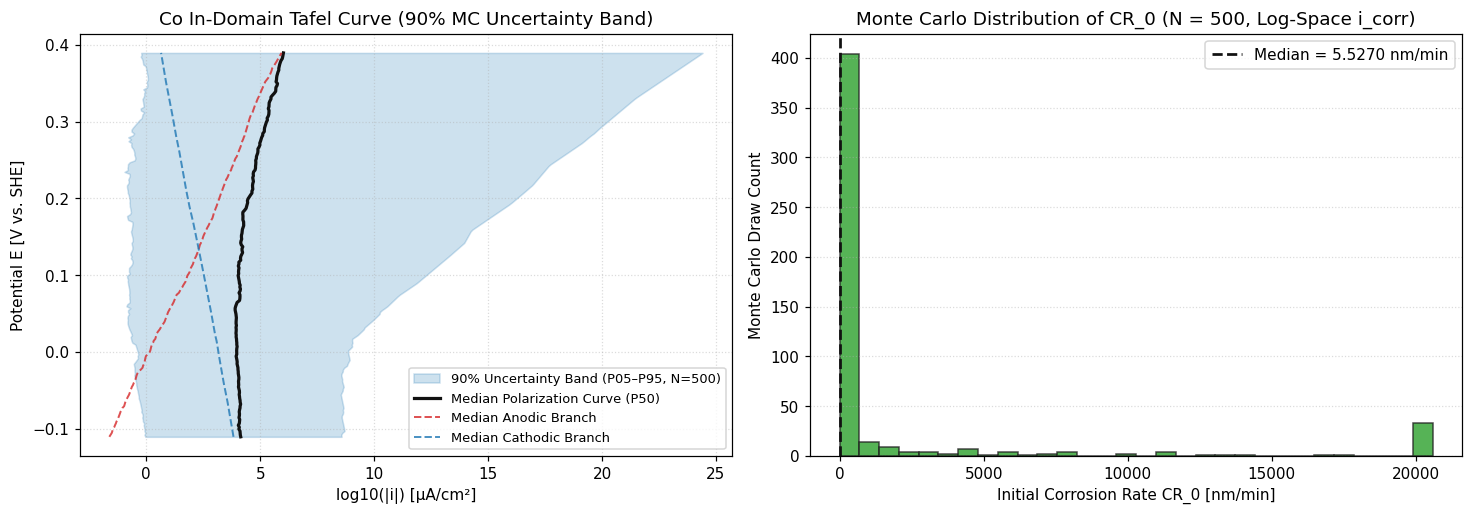

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(13.5, 4.8))
plot_tafel_uncertainty_band(mc_in, ax=axes[0], title='Co In-Domain Tafel Curve (90% MC Uncertainty Band)')
axes[1].hist(mc_in.cr_nm_min_samples, bins=30, color='#2ca02c', edgecolor='#222222', alpha=0.8)
axes[1].axvline(mc_in.cr_nm_min_summary['p50'], color='#111111', linestyle='--', linewidth=1.8, label=f'Median = {mc_in.cr_nm_min_summary["p50"]:.4f} nm/min')
axes[1].set_xlabel('Initial Corrosion Rate CR_0 [nm/min]')
axes[1].set_ylabel('Monte Carlo Draw Count')
axes[1].set_title('Monte Carlo Distribution of CR_0 (N = 500, Log-Space i_corr)')
axes[1].legend()
axes[1].grid(axis='y', linestyle=':', alpha=0.45)
plt.tight_layout()
plt.show()

### Summary & Recommendations
- **Model Selection**: Random Forest provides strong baseline accuracy, fast inference, direct tree-variance uncertainty estimation, and interpretable feature importances; Gradient Boosted Trees (bootstrap ensemble) and Gaussian Processes (posterior variance) are available through the same `HybridMLPredictor` interface.
- **Physical Guarantees**: Log-space sampling of $\log_{10}(i_{\text{corr}})$ and hard clipping of $(\beta_a, \beta_c) \in [20, 500]\text{ mV/dec}$ guarantee physically valid Polarization Curve uncertainty bands and strictly non-negative Corrosion Rates.
- **Safe Deployment**: Always surface the `ApplicabilityDomainResult` **Confidence Tier** and experimental gap guidance alongside ML predictions in downstream galvanic coupling and recipe comparison views.